# Week 6 · Topic 4 — Apply, Lambda and Finishing Up

**Box we are building: STORE + PROCESS, the whole job**

A `lambda` is a `def` you don't bother naming, for a one-line function you are
only going to use once — usually right inside `.apply()`.

> **Already know this?** Skip to the *Topic 4 Challenge*.

---
## 1. `.apply()` runs a function on every value in a column

Start with a normal function, the way Week 3 taught it.

In [ ]:
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100

def classify(percent):
    if percent >= 100:
        return "OVER LIMIT"
    elif percent >= 90:
        return "WARNING"
    else:
        return "OK"

servers["status"] = servers["percent"].apply(classify)
print(servers)

### Your turn
Write your own single-argument function and `.apply()` it to the `used` column.

In [3]:
# your code here
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["free"] = servers["total"] - servers["used"]

def classify(free):
    if free>= 70:
        return "OK"
    elif free == 55:
        return "Warning"
    else:
        return "Too little space"

servers["space"] =servers["free"].apply(classify)
print(servers)

  hostname region  used  total  free             space
0  srv-001   east    87    100    13  Too little space
1  srv-002   west    99    100     1  Too little space
2  srv-003  south    76    100    24  Too little space
3  srv-009  north    45    100    55           Warning
4  srv-007   east    52    100    48  Too little space
5  srv-005   west    30    100    70                OK
6  srv-008  south    19    100    81                OK
7  srv-004  north    27    100    73                OK
8  srv-006  south    61    100    39  Too little space


---
## 2. `lambda` - the same idea, written inline

`lambda parameters: expression` — that IS the whole function. Only one
expression allowed — no `if`/`elif`/`else` statements, no loops.

In [5]:
double = lambda x: x * 2
print(double(21))     # 42 - same as def double(x): return x * 2

42


```
def classify(p):                    lambda p: (
    if p >= 100:                        "OVER LIMIT" if p >= 100
        return "OVER LIMIT"             else "WARNING" if p >= 90
    elif p >= 90:                       else "OK"
        return "WARNING"             )
    else:
        return "OK"

same logic, same result - a block of statements vs one expression
```

### Your turn
Write `classify` as a lambda with a chained conditional, and check it gives the same result as the `def` version for every row.

In [8]:
# your code here
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["free"] = servers["total"] - servers["used"]

space = lambda free: (
    "OK" if free >= 70
    else "WARNING" if free == 55
    else "Too little space"
)

print(servers["free"].apply(space))



0    Too little space
1    Too little space
2    Too little space
3             WARNING
4    Too little space
5                  OK
6                  OK
7                  OK
8    Too little space
Name: free, dtype: str


---
## 3. `.apply()` with a lambda, and `sort_values(key=...)`

lambda earns its place exactly here — a function small enough to write inline,
used exactly once, right where it is needed.

In [ ]:


servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
print(servers.sort_values("hostname", key=lambda col: col.str.lower()))

KeyError: 'percent'

### Your turn
Use `.apply()` with a lambda to add a column `region_upper` — the `region` column, in capitals.

In [3]:
# your code here

import pandas as pd

servers = pd.read_csv("servers.csv")

servers["region_upper"] = servers["region"].apply( lambda r: r.upper())

print(servers)

  hostname region  used  total region_upper
0  srv-001   east    87    100         EAST
1  srv-002   west    99    100         WEST
2  srv-003  south    76    100        SOUTH
3  srv-009  north    45    100        NORTH
4  srv-007   east    52    100         EAST
5  srv-005   west    30    100         WEST
6  srv-008  south    19    100        SOUTH
7  srv-004  north    27    100        NORTH
8  srv-006  south    61    100        SOUTH


---
## 4. Summarising, saving, and a first chart

`describe()` for a quick overview, `.to_csv()` to save, and one chart — straight
off a DataFrame. In a notebook, calling `.plot()` shows the chart inline.

In [2]:
%pip install matplotlib


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 161.1 MB/s eta 0:00:01
   --- ------------------------------------ 0.8/9.5 MB 1.5 MB/s eta 0:00:06
   --- ------------------------------------ 0.8/9.5 MB 1.5 MB/s eta 0:00:06
   ---- ----------------------------------- 1.0/9.5 MB 1.3 MB/s eta 0:00:07
   ----- ---------------------------------- 1.3/9.5 MB 1.2 MB/s eta 0:00:07
   ------ --------------------------------- 1.6/9.5 MB 1.1 MB/s eta 0:00:07
   ------- -------------------------------- 1.8/9.5 MB 1.2 MB/s eta 0:00:07
   -------- ------------------------------- 2.1/9.5 MB 1.1 MB/s eta 0:00:07
   --------- ------------------------------ 2.4/9.5 MB 1.2 MB/s eta 0:00:06
   ----------- -----------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:
import matplotlib.pyplot as plt

print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["status"].value_counts().plot(kind="bar", title="Servers by status")
plt.tight_layout()
plt.show()

NameError: name 'servers' is not defined

### Your turn
Make a bar chart of servers per region instead of per status.

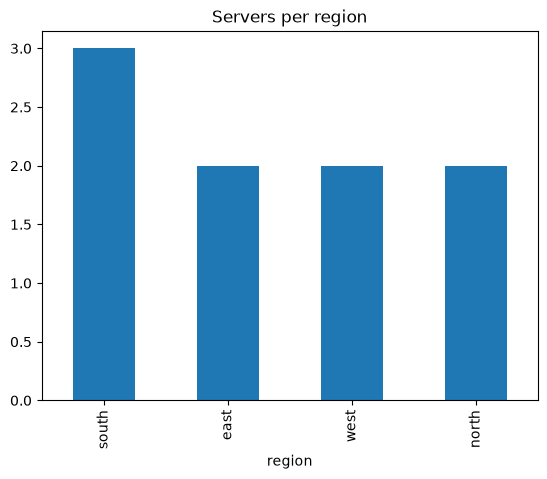

In [4]:
# your code here
import matplotlib.pyplot as plt
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["region"].value_counts().plot(kind="bar", title="Servers per region")
plt.tight_layout
plt.show()


---
## Topic 4 Challenge

Load `servers.csv`, add `percent` and `status` (via `.apply()` with a lambda),
save the result to a new CSV, and produce one bar chart of the status counts.

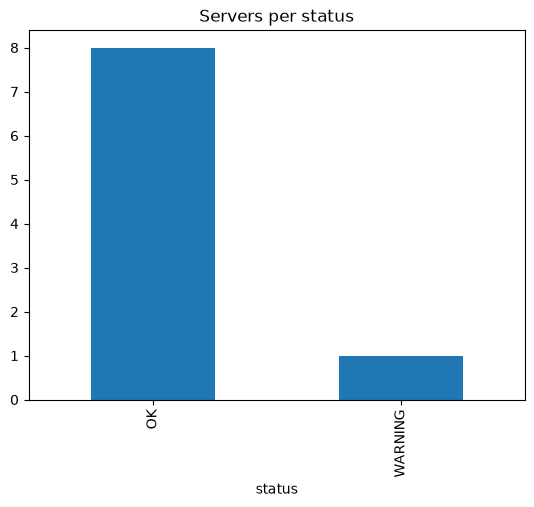

In [6]:
# your code here
import matplotlib.pyplot as plt
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["percent"] = (servers["used"]/servers["total"])*100
servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)

servers.to_csv("server_2.csv", index = False)
servers["status"].value_counts().plot(kind="bar", title="Servers per status")
plt.tight_layout
plt.show()

---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | `df["clean_text"] = df["text"].apply(lambda t: t.strip().lower())` |
| **Cyber Security** | `df["flag"] = df["failed"].apply(lambda n: n >= 3)` |
| **IT** | `df.sort_values("hostname", key=lambda c: c.str.lower())` |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| a lambda with an `if` statement (not an expression) | `SyntaxError` | lambda only allows one expression — use chained `if/else`, or write a `def` |
| reusing the same lambda logic in three places | works, but repeats the logic three times | that is the sign you wanted a named function, not a lambda |
| forgetting `.apply()` and just writing `column.classify()` | `AttributeError` | `.apply(function)` runs your function on every value — the function itself is not a method on the column |
| calling `.plot()` in a plain script and seeing nothing | no chart appears | add `plt.show()` (script) — a notebook shows it automatically |

## Go deeper

`examples/01_apply_and_lambda.py` — apply, lambda syntax, chained conditionals, sort key
`examples/02_summarizing_saving_and_charting.py` — describe, to_csv, a first chart

---
## Recap

| You can now | Using |
|---|---|
| apply a function to a whole column | `column.apply(function)` |
| write a small inline function | `lambda x: expression` |
| choose lambda vs a named function | one-line, used once → lambda; reused or complex → `def` |
| get a quick overview | `.describe()` |
| save a result | `.to_csv(path, index=False)` |
| chart straight from a DataFrame | `.plot(kind=...)` |

**You now have all of CW1's toolkit.** Your mini-project this week closes it out.